In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex

#import csv

import numpy as np
from numpy import diff

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm
from statsmodels.graphics.gofplots import qqplot

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import itertools

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.analysis import Derive_Smooth_And_Find_Peaks
from scientific_utils.battery.plotting import Matplotlib_Data_Smoothed_Residuals
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.general.plotting import Matplotlib_XvsY_Per_Cycle
from scientific_utils.statistics.plotting import Matplotlib_FFT_Spectra_Comparison
from scientific_utils.statistics.plotting import Matplotlib_Histogram_Residuals
from scientific_utils.statistics.plotting import Matplotlib_QQ_Plot
from scientific_utils.statistics.plotting import Matplotlib_Residuals_Vs_Value

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the .pkl file ########
########## Open the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_charge_equidistant_cycling.pkl', 'rb') as f:
    list_of_dataframes_of_CP_charge_equidistant_cycling = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_discharge_equidistant_cycling.pkl', 'rb') as f:
    list_of_dataframes_of_CP_discharge_equidistant_cycling = pickle.load(f)


In [6]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [7]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [8]:
# only these cycles are plotted below (the cycle given by cycle_to_save is always plotted and saved); None -> all 50 cycles
cycles_to_show = [1, 25, 50]

In [9]:
#################################### Plotting of the Charging Curves ################################

In [10]:
# defining the arguments for the function
list_of_dataframes = list_of_dataframes_of_CP_charge_equidistant_cycling
x_values_column_name = 'Voltage (V)'
y_values_column_name = 'Capacity (mAh)'
percent_of_points_used_for_smoothing = [0.25 for x in range(len(list_of_dataframes))]
prominence_min_max_for_peakfind = [(0.20, 4.0) for x in range(len(list_of_dataframes))] 
percent_of_points_used_for_peakfind = [0.06 for x in range(len(list_of_dataframes))]
positv_or_negativ_peak = +1
dYdX_column_name_new = 'dQ/dV / mAh/V'

# application of the Function for derive and smoothed raw data: curves, peaks per curve and all peaks in one dataframe
list_of_dataframes_of_dQdV_CP_charge_equidistant_cycling, list_of_dataframes_of_dQdV_CP_charge_peaks_cycling, dataframes_of_dQdV_CP_charge_peaks_cycling = Derive_Smooth_And_Find_Peaks(list_of_dataframes, x_values_column_name, y_values_column_name, percent_of_points_used_for_smoothing, prominence_min_max_for_peakfind, percent_of_points_used_for_peakfind, positv_or_negativ_peak, dYdX_column_name_new) # one call returns all three results

#print(list_of_dataframes_of_dQdV_CP_charge_peaks)


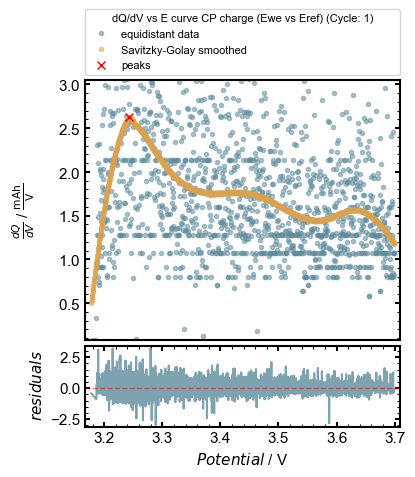

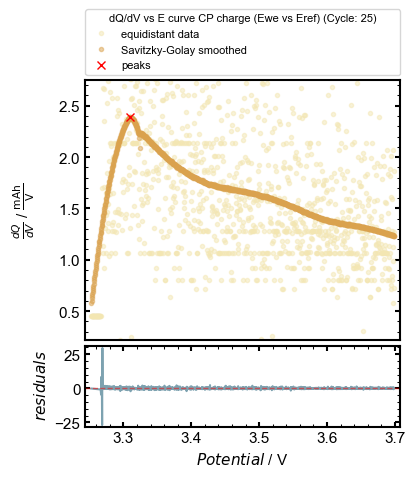

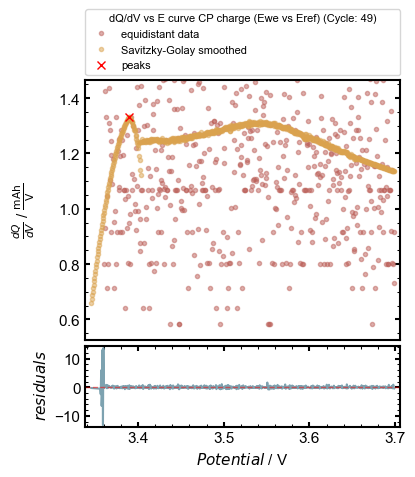

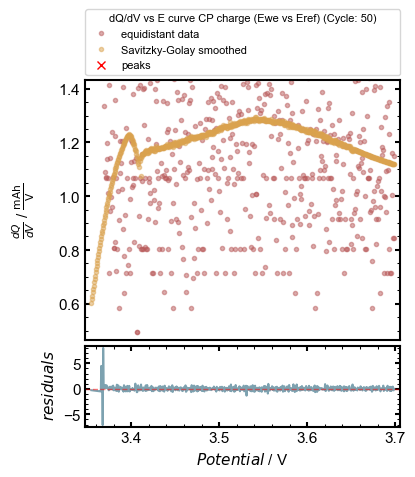

In [11]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant_cycling
x_values_column_name = 'Voltage (V)'
y_values_column_name = 'dQ/dV / mAh/V'
y_values_smoothed_column_name = 'Savgol-Filter dQ/dV / mAh/V'
list_of_dataframes_peaks = list_of_dataframes_of_dQdV_CP_charge_peaks_cycling
x_peak_values_column_name = 'Peak Savgol-Filter Voltage (V)'
y_peak_values_column_name = 'Peak Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 49
additional_name = 'charge'
legend_title = 'dQ/dV vs E curve CP charge (Ewe vs Eref)'

Matplotlib_Data_Smoothed_Residuals(list_of_dataframes, x_values_column_name, y_values_column_name, y_values_smoothed_column_name, list_of_dataframes_peaks, x_peak_values_column_name, y_peak_values_column_name, cycle_to_save, additional_name, legend_title, cycles_to_show=cycles_to_show)

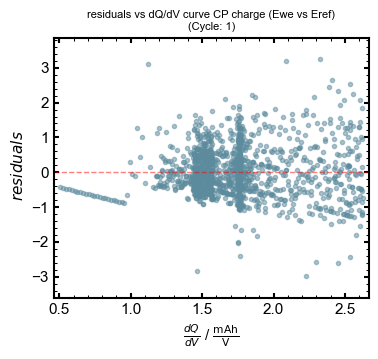

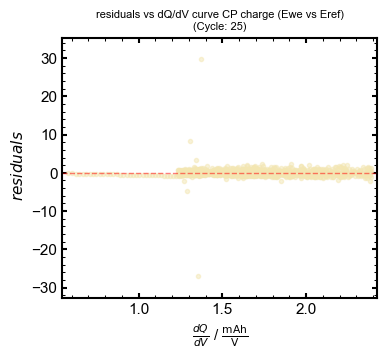

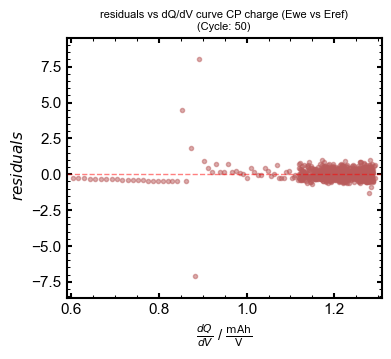

In [12]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant_cycling
x_values_column_name = 'Savgol-Filter dQ/dV / mAh/V'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1 
additional_name = 'charge'
legend_title = 'residuals vs dQ/dV curve CP charge (Ewe vs Eref)'

Matplotlib_Residuals_Vs_Value(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, legend_title, cycles_to_show=cycles_to_show)

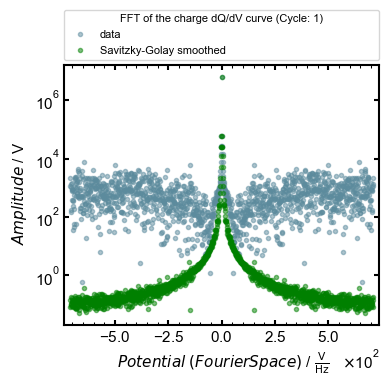

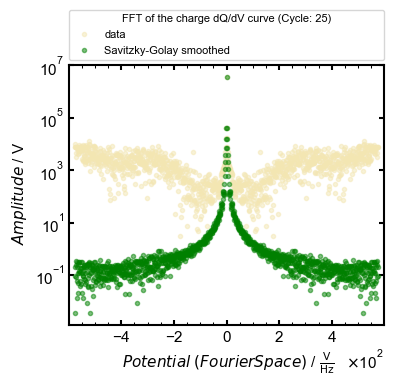

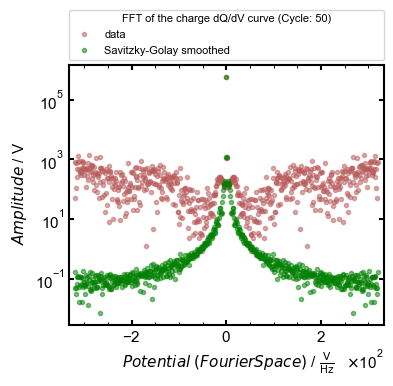

In [13]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant_cycling
x_values_column_name = 'Voltage (V)'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1 
additional_name = 'charge'
legend_title = 'FFT of the charge dQ/dV curve'
y_ax_label = r' $Amplitude$ / V'
x_ax_label = r' $Potential$ $(Fourier Space)$ / $\frac{\mathsf{V}}{\mathsf{Hz}}$' 

Matplotlib_FFT_Spectra_Comparison(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, legend_title, y_ax_label, x_ax_label, cycles_to_show=cycles_to_show)


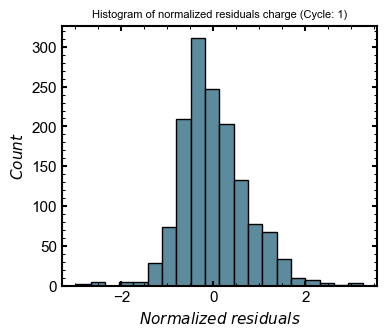

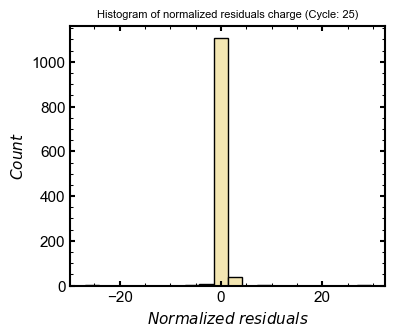

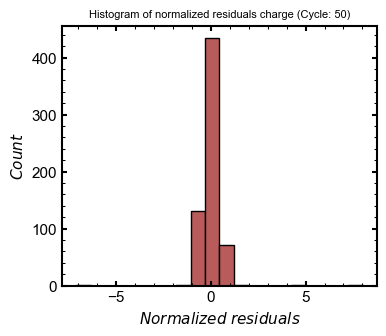

In [14]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant_cycling
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1
additional_name = 'charge'
legend_title = "Histogram of normalized residuals charge"

Matplotlib_Histogram_Residuals(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, legend_title, cycles_to_show=cycles_to_show)


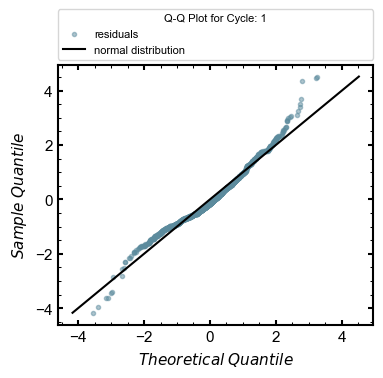

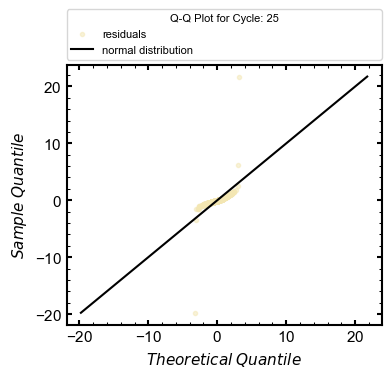

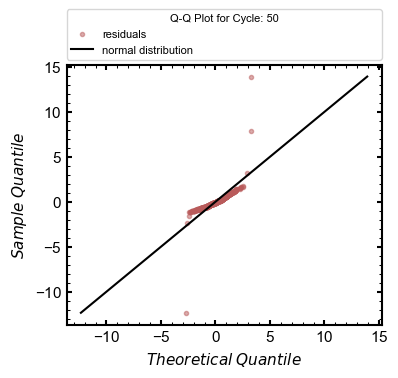

In [15]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_charge_equidistant_cycling
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1
additional_name = 'charge'

Matplotlib_QQ_Plot(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, cycles_to_show=cycles_to_show)

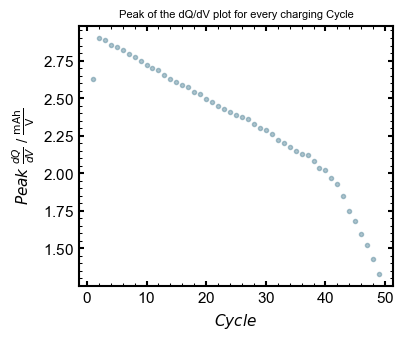

In [16]:
#print(dataframe_of_dQdV_CP_charge_peaks_cycling)

dataframe = dataframes_of_dQdV_CP_charge_peaks_cycling
x_values_column_name = 'Cycle'
y_values_column_name = 'Peak Savgol-Filter dQ/dV / mAh/V'
y_ax_label = r'$Peak$ $ \frac{dQ}{dV}$ / $\frac{\mathsf{mAh}}{\mathsf{V}}$'
x_ax_label = r'$Cycle$'
cycle_to_save = 1
additional_name = 'Peak_of_the_dQdV_plot_for_every_charging_Cycle'
legend_title = 'Peak of the dQ/dV plot for every charging Cycle'

Matplotlib_XvsY_Per_Cycle(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, cycle_to_save, additional_name, legend_title)

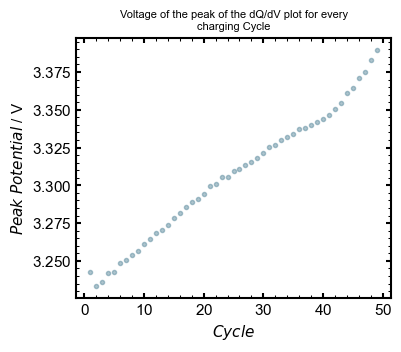

In [17]:
dataframe = dataframes_of_dQdV_CP_charge_peaks_cycling
x_values_column_name = 'Cycle'
y_values_column_name = 'Peak Savgol-Filter Voltage (V)'
y_ax_label = r'$Peak$ $Potential$ / V'
x_ax_label = r'$Cycle$'
cycle_to_save = 1
additional_name = 'Voltage_of_the_peak_of_the_dQdV_plot_for_every_charging_Cycle'
legend_title = 'Voltage of the peak of the dQ/dV plot for every charging Cycle'

Matplotlib_XvsY_Per_Cycle(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, cycle_to_save, additional_name, legend_title)

In [18]:
#################################### Plotting of the Discharging Curves ################################

In [19]:
# defining the arguments for the function
list_of_dataframes = list_of_dataframes_of_CP_discharge_equidistant_cycling
x_values_column_name = 'Voltage (V)'
y_values_column_name = 'Capacity (mAh)'
percent_of_points_used_for_smoothing = [0.08 for x in range(len(list_of_dataframes))]
prominence_min_max_for_peakfind = [(0.20, 4.0) for x in range(len(list_of_dataframes))] 
percent_of_points_used_for_peakfind = [0.06 for x in range(len(list_of_dataframes))]
positv_or_negativ_peak = -1
dYdX_column_name_new = 'dQ/dV / mAh/V'

# application of the Function for derive and smoothed raw data: curves, peaks per curve and all peaks in one dataframe
list_of_dataframes_of_dQdV_CP_discharge_equidistant_cycling, list_of_dataframes_of_dQdV_CP_discharge_peaks_cycling, dataframes_of_dQdV_CP_discharge_peaks_cycling = Derive_Smooth_And_Find_Peaks(list_of_dataframes, x_values_column_name, y_values_column_name, percent_of_points_used_for_smoothing, prominence_min_max_for_peakfind, percent_of_points_used_for_peakfind, positv_or_negativ_peak, dYdX_column_name_new) # one call returns all three results

#print(list_of_dataframes_of_dQdV_CP_charge_peaks)


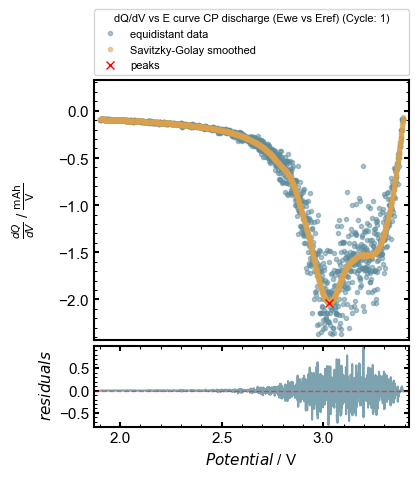

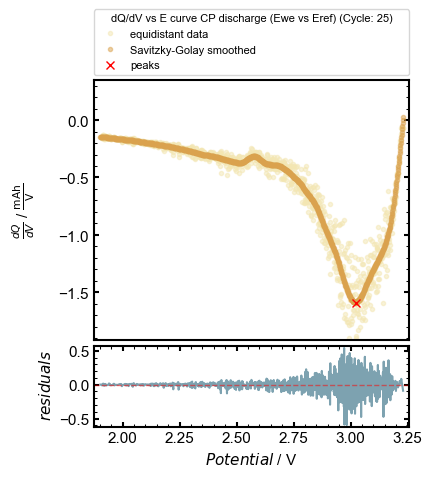

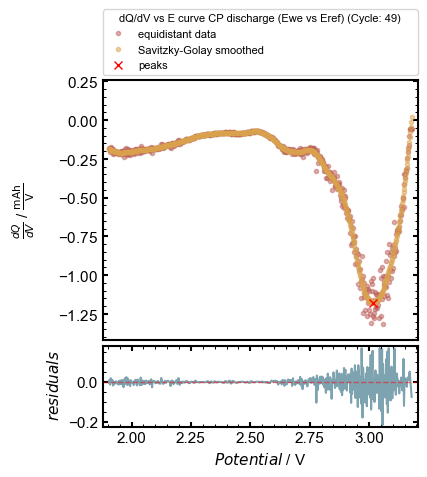

In [20]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant_cycling
x_values_column_name = 'Voltage (V)'
y_values_column_name = 'dQ/dV / mAh/V'
y_values_smoothed_column_name = 'Savgol-Filter dQ/dV / mAh/V'
list_of_dataframes_peaks = list_of_dataframes_of_dQdV_CP_discharge_peaks_cycling
x_peak_values_column_name = 'Peak Savgol-Filter Voltage (V)'
y_peak_values_column_name = 'Peak Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 49
additional_name = 'discharge'
legend_title = 'dQ/dV vs E curve CP discharge (Ewe vs Eref)'

Matplotlib_Data_Smoothed_Residuals(list_of_dataframes, x_values_column_name, y_values_column_name, y_values_smoothed_column_name, list_of_dataframes_peaks, x_peak_values_column_name, y_peak_values_column_name, cycle_to_save, additional_name, legend_title, cycles_to_show=cycles_to_show)

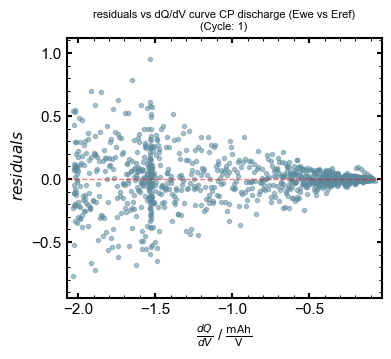

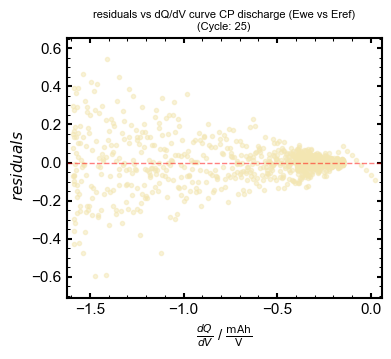

In [21]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant_cycling
x_values_column_name = 'Savgol-Filter dQ/dV / mAh/V'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1
additional_name = 'discharge' 
legend_title = 'residuals vs dQ/dV curve CP discharge (Ewe vs Eref)'

Matplotlib_Residuals_Vs_Value(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, legend_title, cycles_to_show=cycles_to_show)

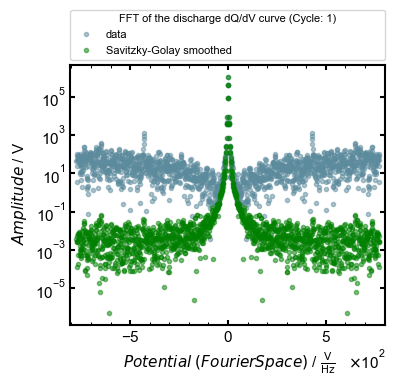

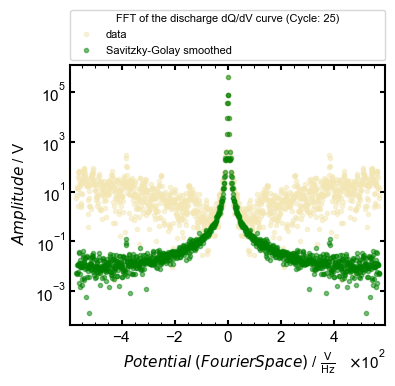

In [22]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant_cycling
x_values_column_name = 'Voltage (V)'
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1 
additional_name = 'discharge'
legend_title = 'FFT of the discharge dQ/dV curve'
y_ax_label = r' $Amplitude$ / V'
x_ax_label = r' $Potential$ $(Fourier Space)$ / $\frac{\mathsf{V}}{\mathsf{Hz}}$'

Matplotlib_FFT_Spectra_Comparison(list_of_dataframes, x_values_column_name, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, legend_title, y_ax_label, x_ax_label, cycles_to_show=cycles_to_show)


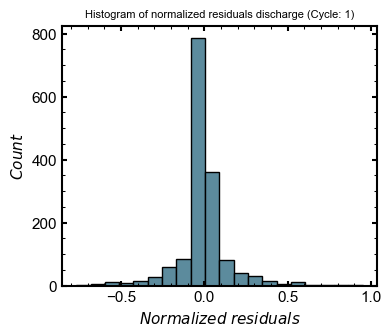

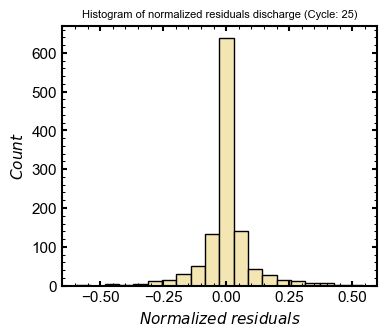

In [23]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant_cycling
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1
additional_name = 'discharge'
legend_title = "Histogram of normalized residuals discharge"

Matplotlib_Histogram_Residuals(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, legend_title, cycles_to_show=cycles_to_show)


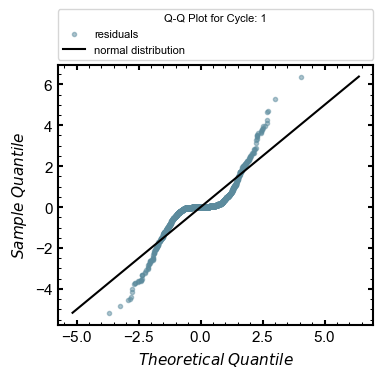

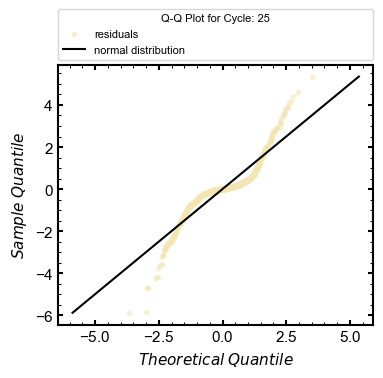

In [24]:
list_of_dataframes = list_of_dataframes_of_dQdV_CP_discharge_equidistant_cycling
y_values_column_name_first = 'dQ/dV / mAh/V'
y_values_column_name_second = 'Savgol-Filter dQ/dV / mAh/V'
cycle_to_save = 1
additional_name = 'discharge'

Matplotlib_QQ_Plot(list_of_dataframes, y_values_column_name_first, y_values_column_name_second, cycle_to_save, additional_name, cycles_to_show=cycles_to_show)

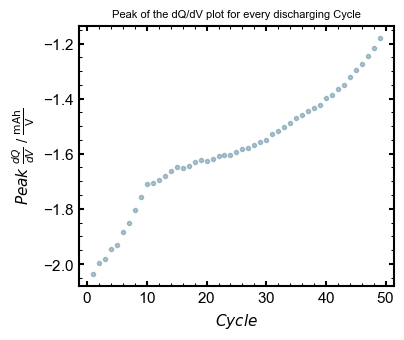

In [25]:
#print(dataframe_of_dQdV_CP_charge_peaks_cycling)

dataframe = dataframes_of_dQdV_CP_discharge_peaks_cycling
x_values_column_name = 'Cycle'
y_values_column_name = 'Peak Savgol-Filter dQ/dV / mAh/V'
y_ax_label = r'$Peak$ $ \frac{dQ}{dV}$ / $\frac{\mathsf{mAh}}{\mathsf{V}}$'
x_ax_label = r'$Cycle$'
cycle_to_save = 1 
additional_name = 'Peak_of_the_dQdV_plot_for_every_discharging_Cycle'
legend_title = 'Peak of the dQ/dV plot for every discharging Cycle'

Matplotlib_XvsY_Per_Cycle(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, cycle_to_save, additional_name, legend_title)

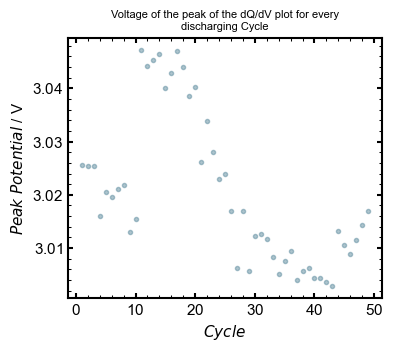

In [26]:
dataframe = dataframes_of_dQdV_CP_discharge_peaks_cycling
x_values_column_name = 'Cycle'
y_values_column_name = 'Peak Savgol-Filter Voltage (V)'
y_ax_label = r'$Peak$ $Potential$ / V'
x_ax_label = r'$Cycle$'
cycle_to_save = 1
additional_name = 'Voltage_of_the_peak_of_the_dQdV_plot_for_every_discharging_Cycle'
legend_title = 'Voltage of the peak of the dQ/dV plot for every discharging Cycle'

Matplotlib_XvsY_Per_Cycle(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, cycle_to_save, additional_name, legend_title)

In [27]:
########## Save the data as .pkl ##########
##### Charge Curves
with open('../data/Batt15/processed/dataframes_of_dQdV_CP_charge_peaks_cycling.pkl', 'wb') as f:
    pickle.dump(dataframes_of_dQdV_CP_charge_peaks_cycling, f)
##### Discharge Curves
with open('../data/Batt15/processed/dataframes_of_dQdV_CP_discharge_peaks_cycling.pkl', 'wb') as f:
    pickle.dump(dataframes_of_dQdV_CP_discharge_peaks_cycling, f)  